<a href="https://colab.research.google.com/github/RizkiHadiono/244107020198-Pembelajaran-Mesin/blob/main/JS13_244107020198_MOKHAMAD_RIZKI_HADIONO_SINGGIH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Jobsheet 13: Artificial Neural Network (ANN) dan Evaluasi Classifier

**Nama:** Mokhamad Rizki Hadiono Singgih  
**NIM:** 244107020198

## Daftar isi

1. Evaluasi Classifier: confusion matrix, accuracy, precision, recall, F1, dan kurva ROC.
2. Praktikum 1: perceptron dan backpropagation manual pada data XOR.
3. Praktikum 2: klasifikasi Iris dengan Keras.
4. Praktikum 3: regresi harga rumah dengan Keras.
5. Tugas Praktikum: klasifikasi angka tulisan tangan MNIST.
6. Kesimpulan.

## Lingkungan kerja

Seluruh eksperimen memakai seed tetap agar hasil dapat diulang. Versi library dicetak pada sel berikut.

In [ ]:
%matplotlib inline

import time
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, precision_score, recall_score,
                             f1_score, cohen_kappa_score,
                             roc_curve, auc, roc_auc_score,
                             mean_squared_error, r2_score)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
pd.set_option('display.width', 120)
sns.set_theme(style='whitegrid')

print('TensorFlow :', tf.__version__)
print('NumPy      :', np.__version__)
print('Pandas     :', pd.__version__)

TensorFlow : 2.21.0
NumPy      : 2.5.3
Pandas     : 3.1.0


# Bagian 1: Evaluasi Classifier

Model klasifikasi tidak cukup dinilai dari satu angka akurasi. Pada bagian ini seluruh metrik dihitung langsung dari tabel confusion matrix, lalu dibandingkan dengan hasil library scikit-learn, dan ditutup dengan kurva ROC.

## 1.1 Confusion matrix

Confusion matrix membandingkan label aktual dengan label prediksi. Untuk kasus dua kelas terdapat empat sel:

| | Prediksi positif | Prediksi negatif |
|---|---|---|
| **Aktual positif** | True Positive (TP) | False Negative (FN) |
| **Aktual negatif** | False Positive (FP) | True Negative (TN) |

Dari keempat nilai tersebut, metrik evaluasi dihitung sebagai berikut.

$$Accuracy = \frac{TP + TN}{TP + TN + FP + FN}$$

$$Precision = \frac{TP}{TP + FP}$$

$$Recall = \frac{TP}{TP + FN}$$

$$F1 = 2 \times \frac{Precision \times Recall}{Precision + Recall}$$

## Langkah 1: Menyiapkan model k-NN pada dataset Iris

Dataset Iris memiliki tiga kelas (setosa, versicolor, virginica). Model k-NN dengan 5 tetangga dipakai sebagai contoh, sama seperti ilustrasi confusion matrix pada jobsheet.

In [ ]:
iris = load_iris()
X_iris, y_iris = iris.data, iris.target
nama_kelas = list(iris.target_names)

X_tr, X_te, y_tr, y_te = train_test_split(
    X_iris, y_iris, test_size=0.3, random_state=SEED, stratify=y_iris
)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_tr, y_tr)
y_pred = knn.predict(X_te)

print('Jumlah data latih :', len(y_tr))
print('Jumlah data uji   :', len(y_te))
print('Akurasi model k-NN:', round(accuracy_score(y_te, y_pred), 4))

Jumlah data latih : 105
Jumlah data uji   : 45
Akurasi model k-NN: 0.9778


## Langkah 2: Menampilkan tabel confusion matrix

Baris menunjukkan label aktual, kolom menunjukkan hasil prediksi. Nilai pada diagonal adalah prediksi yang benar.

Confusion matrix (baris = aktual, kolom = prediksi):
            setosa  versicolor  virginica
setosa          15           0          0
versicolor       0          15          0
virginica        0           1         14


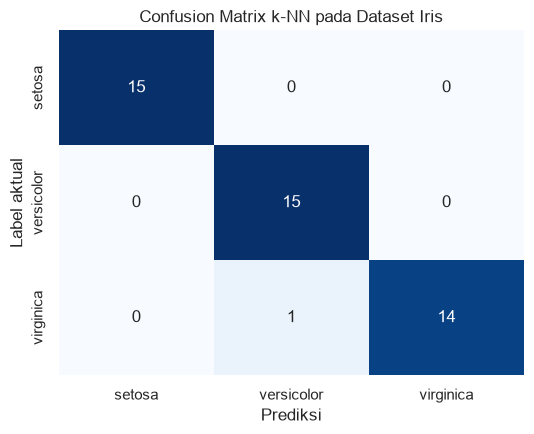

In [ ]:
cm = confusion_matrix(y_te, y_pred, labels=[0, 1, 2])
print('Confusion matrix (baris = aktual, kolom = prediksi):')
print(pd.DataFrame(cm, index=nama_kelas, columns=nama_kelas))

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=nama_kelas, yticklabels=nama_kelas)
plt.xlabel('Prediksi')
plt.ylabel('Label aktual')
plt.title('Confusion Matrix k-NN pada Dataset Iris')
plt.tight_layout()
plt.show()

## Langkah 3: Menghitung TP, TN, FP, FN dan metrik secara manual

Untuk masalah tiga kelas, perhitungan dilakukan dengan pendekatan satu kelas melawan kelas lainnya (one versus rest). Setiap kelas diperlakukan sebagai positif, dua kelas lainnya digabung menjadi negatif.

In [ ]:
total = cm.sum()
baris = []

for i, nama in enumerate(nama_kelas):
    TP = int(cm[i, i])
    FN = int(cm[i, :].sum() - TP)
    FP = int(cm[:, i].sum() - TP)
    TN = int(total - TP - FN - FP)

    acc = (TP + TN) / total
    prec = TP / (TP + FP) if (TP + FP) else 0.0
    rec = TP / (TP + FN) if (TP + FN) else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0

    baris.append({'Kelas': nama, 'TP': TP, 'TN': TN, 'FP': FP, 'FN': FN,
                  'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1': f1})

manual_df = pd.DataFrame(baris)
display(manual_df.round(4))

print('Accuracy manual (semua kelas):',
      round(np.trace(cm) / total, 4))
print('Precision manual (rata-rata kelas):', round(manual_df['Precision'].mean(), 4))
print('Recall manual (rata-rata kelas)   :', round(manual_df['Recall'].mean(), 4))
print('F1 manual (rata-rata kelas)       :', round(manual_df['F1'].mean(), 4))

,Kelas,TP,TN,FP,FN,Accuracy,Precision,Recall,F1
0,setosa,15,30,0,0,1.0000,1.0000,1.0000,1.0000
1,versicolor,15,29,1,0,0.9778,0.9375,1.0000,0.9677
2,virginica,14,30,0,1,0.9778,1.0000,0.9333,0.9655


Accuracy manual (semua kelas): 0.9778
Precision manual (rata-rata kelas): 0.9792
Recall manual (rata-rata kelas)   : 0.9778
F1 manual (rata-rata kelas)       : 0.9778


## Langkah 4: Membandingkan hasil manual dengan scikit-learn

Tabel berikut memastikan perhitungan manual sudah benar. Nilai precision, recall, dan F1 untuk setiap kelas harus sama dengan keluaran `classification_report`. Nilai rata-rata pada tabel manual ekuivalen dengan `macro avg`.

In [ ]:
sk_df = pd.DataFrame({
    'Kelas': nama_kelas,
    'Precision': precision_score(y_te, y_pred, average=None, zero_division=0),
    'Recall': recall_score(y_te, y_pred, average=None, zero_division=0),
    'F1': f1_score(y_te, y_pred, average=None, zero_division=0),
})
display(sk_df.round(4))

ringkas = pd.DataFrame([
    {'Sumber': 'Manual (macro)', 'Accuracy': np.trace(cm) / total,
     'Precision': manual_df['Precision'].mean(),
     'Recall': manual_df['Recall'].mean(), 'F1': manual_df['F1'].mean()},
    {'Sumber': 'scikit-learn (macro)',
     'Accuracy': accuracy_score(y_te, y_pred),
     'Precision': precision_score(y_te, y_pred, average='macro', zero_division=0),
     'Recall': recall_score(y_te, y_pred, average='macro', zero_division=0),
     'F1': f1_score(y_te, y_pred, average='macro', zero_division=0)},
])
display(ringkas.round(4))

print('Cohen kappa:', round(cohen_kappa_score(y_te, y_pred), 4))
print()
print(classification_report(y_te, y_pred, target_names=nama_kelas, zero_division=0))

,Kelas,Precision,Recall,F1
0,setosa,1.0000,1.0000,1.0000
1,versicolor,0.9375,1.0000,0.9677
2,virginica,1.0000,0.9333,0.9655


,Sumber,Accuracy,Precision,Recall,F1
0,Manual (macro),0.9778,0.9792,0.9778,0.9778
1,scikit-learn (macro),0.9778,0.9792,0.9778,0.9778


Cohen kappa: 0.9667

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.94      1.00      0.97        15
   virginica       1.00      0.93      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



Kappa mengukur kesepakatan antara prediksi dan label aktual setelah menghapus kesepakatan yang muncul karena kebetulan. Nilainya berkisar 0 sampai 1, makin tinggi makin baik. Accuracy saja bisa menyesatkan pada data tidak seimbang, sedangkan kappa ikut memperhitungkan distribusi kelas.

## 1.2 Kurva ROC

Kurva ROC memplot True Positive Rate terhadap False Positive Rate pada berbagai nilai threshold.

$$TPR = \frac{TP}{TP + FN} \qquad FPR = \frac{FP}{FP + TN}$$

AUC adalah luas di bawah kurva. Nilai 0.5 berarti model tidak lebih baik dari tebakan acak, sedangkan nilai 1.0 berarti pemisahan sempurna.

## Langkah 5: Kurva ROC untuk kasus biner

Agar ROC dapat digambar, salah satu kelas dijadikan positif. Di sini kelas versicolor dijadikan positif dan dua kelas lainnya menjadi negatif.

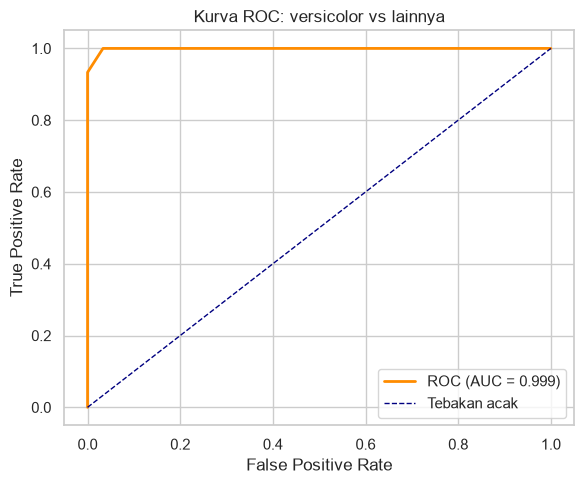

AUC            : 0.9989
AUC (sklearn)  : 0.9989
Jumlah threshold: 5


In [ ]:
y_biner = (y_iris == 1).astype(int)
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(
    X_iris, y_biner, test_size=0.3, random_state=SEED, stratify=y_biner
)

knn_biner = KNeighborsClassifier(n_neighbors=5)
knn_biner.fit(Xb_tr, yb_tr)
proba = knn_biner.predict_proba(Xb_te)[:, 1]

fpr, tpr, thresholds = roc_curve(yb_te, proba)
nilai_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {nilai_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--', label='Tebakan acak')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Kurva ROC: versicolor vs lainnya')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

print('AUC            :', round(nilai_auc, 4))
print('AUC (sklearn)  :', round(roc_auc_score(yb_te, proba), 4))
print('Jumlah threshold:', len(thresholds))

## Langkah 6: Membaca kurva ROC

Kurva pada gambar di atas mendekati sudut kiri atas, yang berarti model mampu memisahkan versicolor dari kelas lain dengan FPR rendah dan TPR tinggi. Nilai AUC di atas 0.9 menandakan pemisahan yang sangat baik.

Catatan penting mengenai pemilihan kurva:

- ROC cocok dipakai ketika distribusi kelas relatif seimbang.
- Precision-Recall lebih informatif ketika kelas positif sangat sedikit, karena FPR menjadi kurang sensitif pada kondisi tersebut.
- Dataset Iris hampir seimbang (50 sampel per kelas), sehingga ROC dan AUC wajar digunakan di sini.

# Bagian 2: Praktikum 1 - Perceptron dan Backpropagation Manual

Jaringan syaraf tiruan meniru cara kerja neuron: menerima input, mengalikan dengan bobot, menjumlahkan, lalu melewatkan hasilnya ke fungsi aktivasi.

$$output = f(WX + b)$$

## Langkah 1: Perceptron sederhana untuk gerbang AND

Perceptron satu lapis memakai fungsi aktivasi step. Bobot diperbarui dengan aturan perceptron: `w = w + lr * error * x`.

In [ ]:
np.random.seed(SEED)

X_and = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_and = np.array([0, 0, 0, 1])

w = np.random.rand(2)
b = np.random.rand(1)
lr = 0.1

def activation(x):
    return 1 if x >= 0 else 0

for epoch in range(10):
    for i in range(len(X_and)):
        z = np.dot(X_and[i], w) + b
        y_pred = activation(z)
        error = y_and[i] - y_pred
        w += lr * error * X_and[i]
        b += lr * error
    print(f'Epoch {epoch + 1:2d} | bobot: {np.round(w, 4)} | bias: {np.round(b, 4)}')

print()
print('Prediksi akhir:', [activation(np.dot(x, w) + b) for x in X_and])

Epoch  1 | bobot: [0.2745 0.8507] | bias: [0.432]
Epoch  2 | bobot: [0.1745 0.7507] | bias: [0.132]
Epoch  3 | bobot: [0.0745 0.6507] | bias: [-0.168]
Epoch  4 | bobot: [0.0745 0.5507] | bias: [-0.268]
Epoch  5 | bobot: [0.0745 0.4507] | bias: [-0.368]
Epoch  6 | bobot: [0.1745 0.4507] | bias: [-0.368]
Epoch  7 | bobot: [0.1745 0.3507] | bias: [-0.468]
Epoch  8 | bobot: [0.1745 0.3507] | bias: [-0.468]
Epoch  9 | bobot: [0.1745 0.3507] | bias: [-0.468]
Epoch 10 | bobot: [0.1745 0.3507] | bias: [-0.468]

Prediksi akhir: [0, 0, 0, 1]


Gerbang AND dapat diselesaikan karena datanya terpisah secara linear. Masalahnya muncul pada XOR: tidak ada satu garis lurus pun yang dapat memisahkan pasangan (0,1) dan (1,0) dari (0,0) dan (1,1). Inilah kelemahan perceptron satu lapis yang dibuktikan Minsky.

## Langkah 2: Dataset XOR

XOR membutuhkan minimal satu hidden layer agar jaringan dapat membentuk batas keputusan non-linear.

In [ ]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

print('X:')
print(X)
print('y:')
print(y.ravel())

X:
[[0. 0.]
 [0. 1.]
 [1. 0.]
 [1. 1.]]
y:
[0. 1. 1. 0.]


## Langkah 3: Inisialisasi bobot dan fungsi aktivasi

Arsitektur awal: 2 neuron input, 2 neuron hidden, 1 neuron output. Semua lapisan memakai sigmoid.

In [ ]:
input_size = 2
hidden_size = 2
output_size = 1
lr = 0.1

np.random.seed(SEED)
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    # x adalah nilai aktivasi (output sigmoid)
    return x * (1 - x)

print('W1:', np.round(W1, 4))
print('W2:', np.round(W2, 4))

W1: [[ 0.4967 -0.1383]
 [ 0.6477  1.523 ]]
W2: [[-0.2342]
 [-0.2341]]


## Langkah 4: Pelatihan dengan forward pass dan backpropagation

Setiap epoch terdiri dari empat tahap:

1. Forward pass: hitung `z1`, `a1`, `z2`, `a2`.
2. Hitung error antara target dan prediksi.
3. Backward pass: hitung gradien untuk setiap bobot memakai aturan rantai.
4. Update bobot dan bias ke arah yang menurunkan error.

In [ ]:
np.random.seed(SEED)
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

loss_history = []

for epoch in range(10000):
    # Forward pass
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Hitung error
    error = y - a2
    loss_history.append(np.mean(np.square(error)))

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot
    W1 += lr * d_W1
    b1 += lr * d_b1
    W2 += lr * d_W2
    b2 += lr * d_b2

    if epoch % 1000 == 0:
        print(f'Epoch {epoch:5d} | Loss: {loss_history[-1]:.6f}')

print()
print('Loss akhir :', round(loss_history[-1], 6))
print('Prediksi   :', np.round(a2.ravel(), 4))
print('Target     :', y.ravel())

Epoch     0 | Loss: 0.255830
Epoch  1000 | Loss: 0.249406
Epoch  2000 | Loss: 0.245445


Epoch  3000 | Loss: 0.204707


Epoch  4000 | Loss: 0.153204
Epoch  5000 | Loss: 0.138691
Epoch  6000 | Loss: 0.133594


Epoch  7000 | Loss: 0.131151
Epoch  8000 | Loss: 0.129749
Epoch  9000 | Loss: 0.128849

Loss akhir : 0.128227
Prediksi   : [0.053  0.4955 0.9509 0.5032]
Target     : [0. 1. 1. 0.]


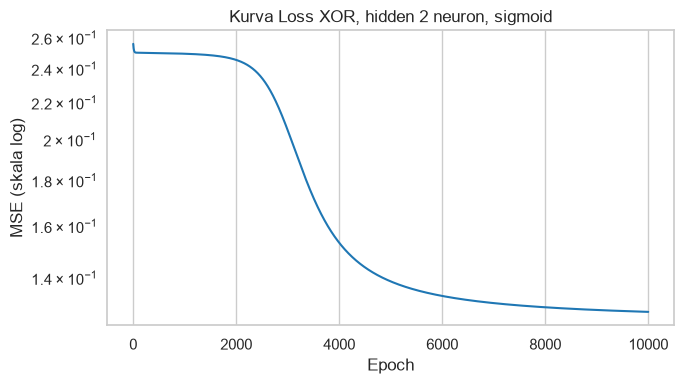

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(loss_history, color='tab:blue')
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('MSE (skala log)')
plt.title('Kurva Loss XOR, hidden 2 neuron, sigmoid')
plt.tight_layout()
plt.show()

Hasil konfigurasi awal belum optimal. Loss berhenti pada 0.1282 dan dua pola XOR tertahan di sekitar 0.5, yaitu pola (0,1) dengan nilai 0.496 dan pola (1,1) dengan nilai 0.503. Jaringan dengan 2 neuron hidden tidak mampu membentuk dua bidang pemisah yang dibutuhkan XOR. Perbaikan konfigurasi ini diuji pada Tugas 1.

## Tugas 1: Variasi jumlah neuron dan fungsi aktivasi

Agar perbandingan adil, seluruh konfigurasi memakai dataset, seed, learning rate, dan jumlah epoch yang sama. Empat konfigurasi diuji:

| Kode | Hidden | Aktivasi hidden |
|---|---|---|
| A | 2 | Sigmoid (konfigurasi awal) |
| B | 3 | Sigmoid |
| C | 2 | ReLU |
| D | 3 | ReLU |

In [ ]:
def relu(x):
    return np.maximum(0, x)

def relu_derivative(z):
    # turunan ReLU memakai nilai z sebelum aktivasi
    return (z > 0).astype(float)

def train_xor(hidden=2, activation='sigmoid', epochs=10000, lr=0.1,
              seed=SEED, verbose=False):
    rng = np.random.RandomState(seed)
    W1 = rng.randn(2, hidden)
    b1 = np.zeros((1, hidden))
    W2 = rng.randn(hidden, 1)
    b2 = np.zeros((1, 1))

    riwayat = []
    for epoch in range(epochs):
        z1 = X @ W1 + b1
        a1 = relu(z1) if activation == 'relu' else sigmoid(z1)
        z2 = a1 @ W2 + b2
        a2 = sigmoid(z2)

        error = y - a2
        riwayat.append(float(np.mean(error ** 2)))

        d_a2 = error * sigmoid_derivative(a2)
        d_W2 = a1.T @ d_a2
        d_b2 = d_a2.sum(axis=0, keepdims=True)

        d_hidden = d_a2 @ W2.T
        if activation == 'relu':
            d_a1 = d_hidden * relu_derivative(z1)
        else:
            d_a1 = d_hidden * sigmoid_derivative(a1)

        d_W1 = X.T @ d_a1
        d_b1 = d_a1.sum(axis=0, keepdims=True)

        W1 += lr * d_W1
        b1 += lr * d_b1
        W2 += lr * d_W2
        b2 += lr * d_b2

        if verbose and epoch % 2000 == 0:
            print(f'  epoch {epoch:5d} | loss {riwayat[-1]:.6f}')

    return {'hidden': hidden, 'activation': activation,
            'history': riwayat, 'prediksi': a2.ravel()}


konfigurasi = [
    ('A', 2, 'sigmoid'),
    ('B', 3, 'sigmoid'),
    ('C', 2, 'relu'),
    ('D', 3, 'relu'),
]

hasil_xor = {}
for kode, hidden, act in konfigurasi:
    print(f'Konfigurasi {kode}: hidden={hidden}, aktivasi={act}')
    hasil_xor[kode] = train_xor(hidden=hidden, activation=act, verbose=True)
    print()

Konfigurasi A: hidden=2, aktivasi=sigmoid
  epoch     0 | loss 0.255830
  epoch  2000 | loss 0.245445
  epoch  4000 | loss 0.153204


  epoch  6000 | loss 0.133594
  epoch  8000 | loss 0.129749



Konfigurasi B: hidden=3, aktivasi=sigmoid
  epoch     0 | loss 0.318245
  epoch  2000 | loss 0.141854
  epoch  4000 | loss 0.020112


  epoch  6000 | loss 0.006270
  epoch  8000 | loss 0.003421



Konfigurasi C: hidden=2, aktivasi=relu
  epoch     0 | loss 0.261648
  epoch  2000 | loss 0.125405
  epoch  4000 | loss 0.125163
  epoch  6000 | loss 0.125096


  epoch  8000 | loss 0.125063

Konfigurasi D: hidden=3, aktivasi=relu
  epoch     0 | loss 0.327478
  epoch  2000 | loss 0.003283


  epoch  4000 | loss 0.001147
  epoch  6000 | loss 0.000666
  epoch  8000 | loss 0.000462


,Kode,Hidden,Aktivasi,Loss awal,Loss akhir,Loss minimum,Epoch loss < 0.01,Prediksi XOR
0,A,2,sigmoid,0.255830,0.128227,0.128227,tidak tercapai,"[0.053, 0.496, 0.951, 0.503]"
1,B,3,sigmoid,0.318245,0.002297,0.002297,5000,"[0.025, 0.953, 0.951, 0.063]"
2,C,2,relu,0.261648,0.125047,0.125047,tidak tercapai,"[0.5, 0.989, 0.5, 0.009]"
3,D,3,relu,0.327478,0.000352,0.000352,1117,"[0.03, 0.986, 0.986, 0.012]"


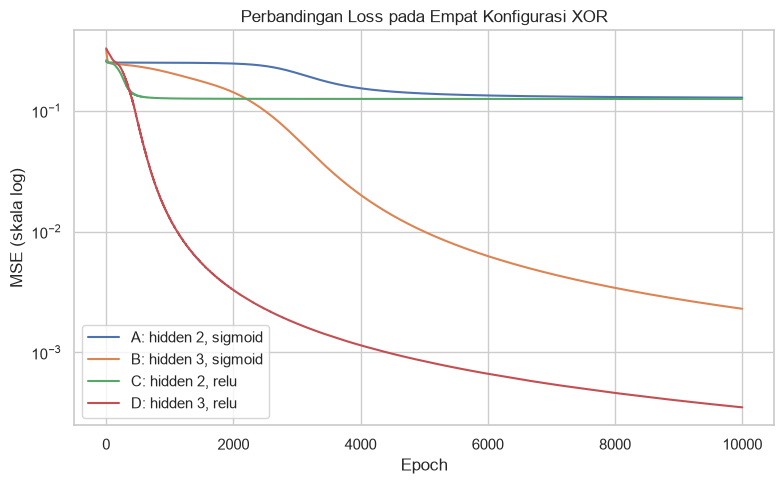

In [ ]:
baris = []
for kode, hidden, act in konfigurasi:
    h = hasil_xor[kode]['history']
    di_bawah = next((i + 1 for i, v in enumerate(h) if v < 0.01), None)
    baris.append({
        'Kode': kode,
        'Hidden': hidden,
        'Aktivasi': act,
        'Loss awal': h[0],
        'Loss akhir': h[-1],
        'Loss minimum': min(h),
        'Epoch loss < 0.01': di_bawah if di_bawah else 'tidak tercapai',
        'Prediksi XOR': np.round(hasil_xor[kode]['prediksi'], 3).tolist(),
    })

tabel_xor = pd.DataFrame(baris)
display(tabel_xor)

plt.figure(figsize=(8, 5))
for kode, hidden, act in konfigurasi:
    plt.plot(hasil_xor[kode]['history'], label=f'{kode}: hidden {hidden}, {act}')
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('MSE (skala log)')
plt.title('Perbandingan Loss pada Empat Konfigurasi XOR')
plt.legend()
plt.tight_layout()
plt.show()

## Pembahasan Tugas 1

Berdasarkan tabel dan grafik di atas, dapat disimpulkan:

1. **Jumlah neuron hidden menentukan apakah model mampu belajar.** Konfigurasi A (2 neuron) gagal konvergen: loss berhenti di 0.1282 dan prediksi untuk pola (0,1) serta (1,1) sama-sama berada di sekitar 0.5. Jaringan dengan 2 neuron hanya mampu membentuk satu bidang pemisah sehingga XOR tidak terpecahkan. Konfigurasi B (3 neuron) turun ke 0.0023 dan keempat pola XOR terprediksi benar (0.025, 0.953, 0.951, 0.063).
2. **ReLU unggul ketika kapasitas neuron mencukupi.** Pada 2 neuron, ReLU juga gagal (loss 0.1250) karena masalahnya bukan pada fungsi aktivasi, melainkan pada jumlah neuron. Setelah hidden layer dinaikkan ke 3 neuron, ReLU mencapai loss 0.00035, jauh lebih rendah daripada sigmoid (0.0023), dan ambang loss 0.01 sudah terlewati pada epoch ke-1117, sedangkan sigmoid baru mencapainya pada epoch ke-5000. ReLU mempercepat konvergensi sekitar empat kali lipat pada kasus ini.
3. **Penyebabnya adalah ukuran gradien.** Turunan sigmoid maksimal 0.25 sehingga gradien menyusut pada setiap lapisan, sedangkan ReLU meneruskan gradien secara utuh untuk nilai positif.
4. **Sigmoid tetap dipakai di lapisan output.** Nilai keluarannya berada pada rentang 0 sampai 1 sehingga dapat dibaca sebagai probabilitas, sedangkan ReLU tidak terbatas di atas.

Kesimpulan praktis: untuk masalah non-linear seperti XOR, menambah neuron pada hidden layer adalah kunci utama. Penggantian fungsi aktivasi menjadi ReLU baru memberi manfaat besar setelah jumlah neuron mencukupi.

# Bagian 3: Praktikum 2 - Klasifikasi Iris dengan Keras

Keras menyediakan API tingkat tinggi di atas TensorFlow sehingga model JST dapat dibangun hanya dengan beberapa baris kode.

## Langkah 1: Memuat data dan menyiapkan label

Label tiga kelas diubah menjadi one-hot encoding. Pada scikit-learn versi baru, parameter `sparse` sudah diganti `sparse_output`.

In [ ]:
iris = load_iris()
X_iris = iris.data
y_iris = iris.target.reshape(-1, 1)

encoder = OneHotEncoder(sparse_output=False)
y_onehot = encoder.fit_transform(y_iris)

X_train, X_test, y_train, y_test = train_test_split(
    X_iris, y_onehot, test_size=0.2, random_state=SEED, stratify=y_iris
)

print('Bentuk X latih :', X_train.shape)
print('Bentuk y latih :', y_train.shape)
print('Bentuk X uji   :', X_test.shape)
print('Contoh label one-hot:', y_train[:3].tolist())

Bentuk X latih : (120, 4)
Bentuk y latih : (120, 3)
Bentuk X uji   : (30, 4)
Contoh label one-hot: [[1.0, 0.0, 0.0], [0.0, 0.0, 1.0], [0.0, 1.0, 0.0]]


## Langkah 2: Membangun dan melatih model

Arsitektur awal: dua hidden layer (10 dan 8 neuron, ReLU) dan satu output layer 3 neuron dengan softmax. Softmax mengubah skor menjadi probabilitas yang jumlahnya 1, cocok untuk klasifikasi multikelas.

In [ ]:
tf.keras.utils.set_random_seed(SEED)

model_iris = keras.Sequential([
    keras.Input(shape=(4,)),
    layers.Dense(10, activation='relu'),
    layers.Dense(8, activation='relu'),
    layers.Dense(3, activation='softmax'),
])

model_iris.compile(optimizer='adam',
                   loss='categorical_crossentropy',
                   metrics=['accuracy'])

model_iris.summary()

mulai = time.perf_counter()
hist_iris = model_iris.fit(X_train, y_train, epochs=50, batch_size=8,
                           validation_split=0.2, verbose=0)
waktu_iris = time.perf_counter() - mulai
print(f'Waktu pelatihan: {waktu_iris:.2f} detik')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 165 (660.00 B)

 Trainable params: 165 (660.00 B)

 Non-trainable params: 0 (0.00 B)

Waktu pelatihan: 7.57 detik


## Langkah 3: Evaluasi model awal

Evaluasi dilakukan pada data uji yang tidak dipakai saat pelatihan.

In [ ]:
loss_uji, acc_uji = model_iris.evaluate(X_test, y_test, verbose=0)
acc_latih = model_iris.evaluate(X_train, y_train, verbose=0)[1]

print(f'Loss data uji    : {loss_uji:.4f}')
print(f'Akurasi data uji : {acc_uji:.4f}')
print(f'Akurasi data latih: {acc_latih:.4f}')
print()

y_pred_iris = np.argmax(model_iris.predict(X_test, verbose=0), axis=1)
y_true_iris = np.argmax(y_test, axis=1)

print(classification_report(y_true_iris, y_pred_iris,
                            target_names=iris.target_names, zero_division=0))

Loss data uji    : 0.2780
Akurasi data uji : 1.0000
Akurasi data latih: 0.9667

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



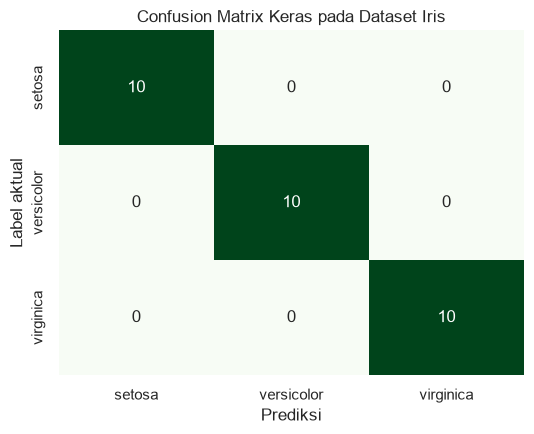

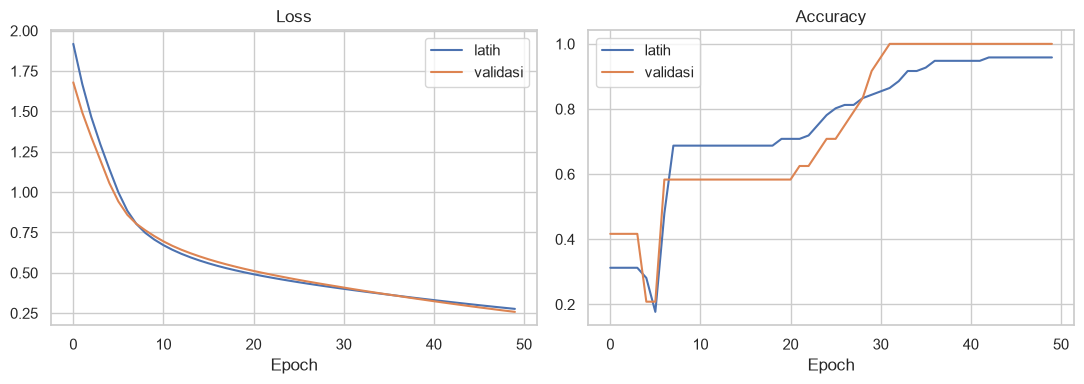

In [ ]:
cm_iris = confusion_matrix(y_true_iris, y_pred_iris, labels=[0, 1, 2])
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm_iris, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Prediksi')
plt.ylabel('Label aktual')
plt.title('Confusion Matrix Keras pada Dataset Iris')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist_iris.history['loss'], label='latih')
ax[0].plot(hist_iris.history['val_loss'], label='validasi')
ax[0].set_title('Loss')
ax[0].set_xlabel('Epoch')
ax[0].legend()

ax[1].plot(hist_iris.history['accuracy'], label='latih')
ax[1].plot(hist_iris.history['val_accuracy'], label='validasi')
ax[1].set_title('Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].legend()

plt.tight_layout()
plt.show()

## Tugas 2: Variasi jumlah neuron hidden layer

Empat arsitektur diuji dengan jumlah epoch, batch size, dan optimizer yang sama. Waktu pelatihan dicatat untuk melihat biaya komputasi setiap konfigurasi.

In [ ]:
def build_iris_model(hidden=(10, 8), activation='relu'):
    tf.keras.utils.set_random_seed(SEED)
    model = keras.Sequential()
    model.add(keras.Input(shape=(4,)))
    for unit in hidden:
        model.add(layers.Dense(unit, activation=activation))
    model.add(layers.Dense(3, activation='softmax'))
    model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model


arsitektur = [(10, 8), (16, 16), (32, 16), (4, 4)]
hasil_iris = {}

for hidden in arsitektur:
    model = build_iris_model(hidden=hidden)
    mulai = time.perf_counter()
    h = model.fit(X_train, y_train, epochs=50, batch_size=8,
                  validation_split=0.2, verbose=0)
    durasi = time.perf_counter() - mulai

    loss_uji, acc_uji = model.evaluate(X_test, y_test, verbose=0)
    acc_latih = model.evaluate(X_train, y_train, verbose=0)[1]

    hasil_iris[hidden] = {
        'model': model, 'history': h.history, 'waktu': durasi,
        'loss_uji': loss_uji, 'acc_uji': acc_uji, 'acc_latih': acc_latih,
    }
    print(f'Hidden {str(hidden):>10} | akurasi latih {acc_latih:.4f} | '
          f'akurasi uji {acc_uji:.4f} | loss uji {loss_uji:.4f} | '
          f'waktu {durasi:.2f} s')

Hidden    (10, 8) | akurasi latih 0.9667 | akurasi uji 1.0000 | loss uji 0.2780 | waktu 7.38 s


Hidden   (16, 16) | akurasi latih 0.9667 | akurasi uji 1.0000 | loss uji 0.2174 | waktu 7.38 s


Hidden   (32, 16) | akurasi latih 0.9750 | akurasi uji 1.0000 | loss uji 0.1111 | waktu 7.11 s


Hidden     (4, 4) | akurasi latih 0.6583 | akurasi uji 0.6667 | loss uji 0.8596 | waktu 7.40 s


,Hidden layer,Jumlah parameter,Akurasi latih,Akurasi uji,Loss uji,Waktu latih (s)
0,"(10, 8)",165,0.9667,1.0000,0.2780,7.3773
1,"(16, 16)",403,0.9667,1.0000,0.2174,7.3784
2,"(32, 16)",739,0.9750,1.0000,0.1111,7.1100
3,"(4, 4)",55,0.6583,0.6667,0.8596,7.3969


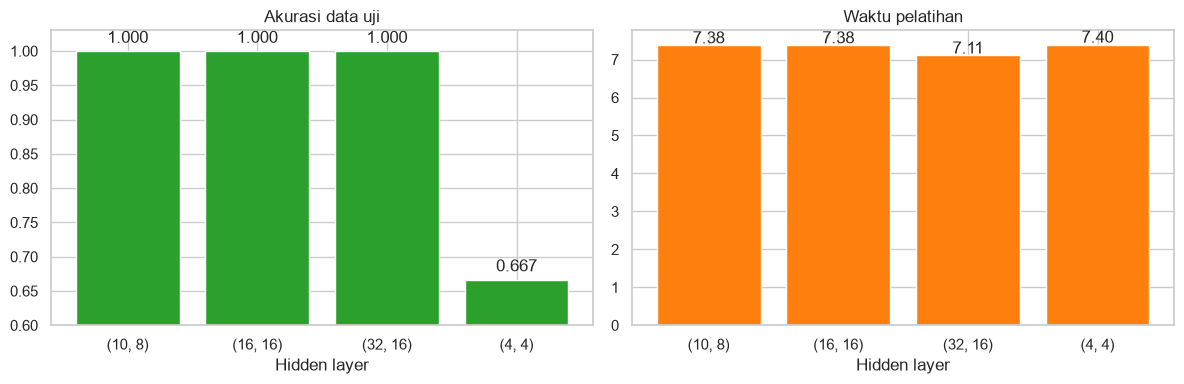

In [ ]:
tabel_iris = pd.DataFrame([
    {'Hidden layer': str(h), 'Jumlah parameter': hasil_iris[h]['model'].count_params(),
     'Akurasi latih': hasil_iris[h]['acc_latih'],
     'Akurasi uji': hasil_iris[h]['acc_uji'],
     'Loss uji': hasil_iris[h]['loss_uji'],
     'Waktu latih (s)': hasil_iris[h]['waktu']}
    for h in arsitektur
])
display(tabel_iris.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
label = [str(h) for h in arsitektur]
ax[0].bar(label, tabel_iris['Akurasi uji'], color='tab:green')
ax[0].set_ylim(0.6, 1.03)
ax[0].set_title('Akurasi data uji')
ax[0].set_xlabel('Hidden layer')
for i, v in enumerate(tabel_iris['Akurasi uji']):
    ax[0].text(i, v + 0.012, f'{v:.3f}', ha='center')

ax[1].bar(label, tabel_iris['Waktu latih (s)'], color='tab:orange')
ax[1].set_title('Waktu pelatihan')
ax[1].set_xlabel('Hidden layer')
for i, v in enumerate(tabel_iris['Waktu latih (s)']):
    ax[1].text(i, v + 0.05, f'{v:.2f}', ha='center')

plt.tight_layout()
plt.show()

## Tugas 3: Perbandingan Sigmoid dan ReLU

Arsitektur dikunci pada (10, 8) agar satu-satunya variabel yang berubah adalah fungsi aktivasi.

In [ ]:
hasil_akt = {}

for act in ['sigmoid', 'relu']:
    model = build_iris_model(hidden=(10, 8), activation=act)
    mulai = time.perf_counter()
    h = model.fit(X_train, y_train, epochs=50, batch_size=8,
                  validation_split=0.2, verbose=0)
    durasi = time.perf_counter() - mulai

    loss_uji, acc_uji = model.evaluate(X_test, y_test, verbose=0)
    hasil_akt[act] = {'history': h.history, 'waktu': durasi,
                      'loss_uji': loss_uji, 'acc_uji': acc_uji}
    print(f'{act:>8} | loss latih akhir {h.history["loss"][-1]:.4f} | '
          f'loss uji {loss_uji:.4f} | akurasi uji {acc_uji:.4f} | '
          f'waktu {durasi:.2f} s')

 sigmoid | loss latih akhir 0.6356 | loss uji 0.6334 | akurasi uji 0.6667 | waktu 6.69 s


    relu | loss latih akhir 0.2768 | loss uji 0.2780 | akurasi uji 1.0000 | waktu 6.72 s


,Aktivasi,Loss latih akhir,Loss validasi akhir,Loss uji,Akurasi uji,Waktu latih (s)
0,sigmoid,0.6356,0.6535,0.6334,0.6667,6.6880
1,relu,0.2768,0.2583,0.2780,1.0000,6.7157


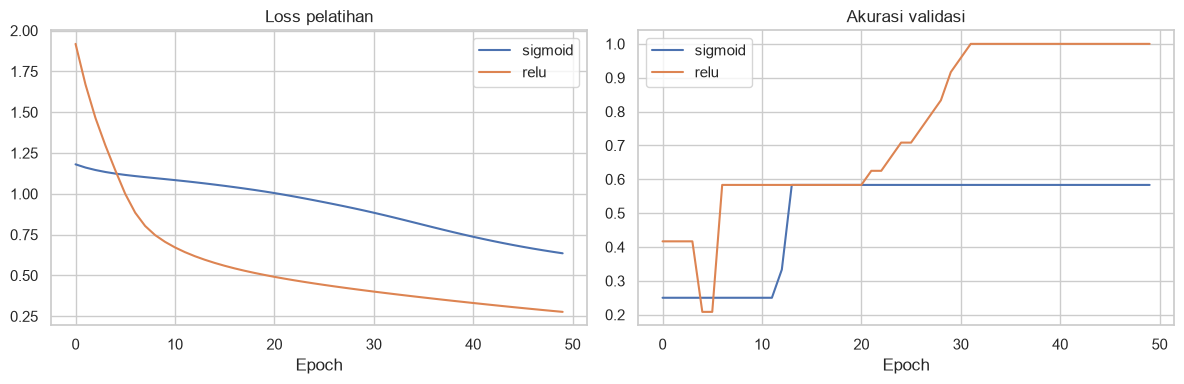

In [ ]:
tabel_akt = pd.DataFrame([
    {'Aktivasi': act,
     'Loss latih akhir': hasil_akt[act]['history']['loss'][-1],
     'Loss validasi akhir': hasil_akt[act]['history']['val_loss'][-1],
     'Loss uji': hasil_akt[act]['loss_uji'],
     'Akurasi uji': hasil_akt[act]['acc_uji'],
     'Waktu latih (s)': hasil_akt[act]['waktu']}
    for act in ['sigmoid', 'relu']
])
display(tabel_akt.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for act in ['sigmoid', 'relu']:
    ax[0].plot(hasil_akt[act]['history']['loss'], label=act)
    ax[1].plot(hasil_akt[act]['history']['val_accuracy'], label=act)

ax[0].set_title('Loss pelatihan')
ax[0].set_xlabel('Epoch')
ax[0].legend()

ax[1].set_title('Akurasi validasi')
ax[1].set_xlabel('Epoch')
ax[1].legend()

plt.tight_layout()
plt.show()

## Pembahasan Tugas 2 dan Tugas 3

**Tugas 2, jumlah neuron.** Dataset Iris hanya memiliki 4 fitur dan 120 baris data latih, sehingga kapasitas model bukan kendala utama selama jumlah neuron memadai. Tiga konfigurasi, yaitu (10, 8), (16, 16), dan (32, 16), sama-sama mencapai akurasi uji 1.0000, tetapi loss uji menurun seiring bertambahnya kapasitas: 0.2780, 0.2174, lalu 0.1111. Artinya model yang lebih besar lebih percaya diri pada prediksinya, meskipun keputusan akhirnya sama.

Sebaliknya, konfigurasi (4, 4) merosot tajam: akurasi latih hanya 0.6583 dan akurasi uji 0.6667. Dengan 4 neuron per lapisan, model tidak cukup kapasitas untuk memisahkan tiga kelas Iris, sehingga terjadi underfitting. Temuan ini menunjukkan bahwa memperbesar model secara berlebihan tidak berguna, tetapi memperkecilnya terlalu jauh justru merusak performa. Waktu pelatihan keempat konfigurasi hampir sama (sekitar 7 sampai 8 detik) karena ukuran data sangat kecil, sehingga biaya komputasi bukan pertimbangan utama di sini. Angka waktu bergantung pada beban perangkat saat dijalankan, jadi yang perlu dibandingkan adalah pola, bukan nilai absolutnya.

**Tugas 3, fungsi aktivasi.** Perbedaan Sigmoid dan ReLU pada Iris sangat jelas. Dengan arsitektur, jumlah epoch, dan optimizer yang sama, Sigmoid berhenti pada akurasi uji 0.6667 dengan loss uji 0.6334, sedangkan ReLU mencapai akurasi uji 1.0000 dengan loss uji 0.2780. Sigmoid membutuhkan epoch jauh lebih banyak untuk mencapai loss rendah karena turunannya maksimal 0.25, sehingga gradien yang sampai ke lapisan awal sangat kecil. Pada dataset kecil dengan hanya 50 epoch, Sigmoid belum sempat konvergen. ReLU tidak mengalami penyusutan gradien untuk nilai positif, sehingga kurva loss turun lebih tajam sejak epoch awal.

**Catatan mengenai ukuran data uji.** Data uji Iris hanya berisi 30 sampel, sehingga akurasi 1.0000 berarti 30 dari 30 prediksi benar. Angka ini tetap perlu dibaca dengan hati-hati karena satu kesalahan saja akan menurunkan akurasi sebesar 3.3 poin persen. Selisih akurasi latih (0.9667) dan akurasi uji (1.0000) bukan tanda overfitting, melainkan efek dari sampel uji yang kecil dan dropout alami pada data latih.

# Bagian 4: Praktikum 3 - Regresi Harga Rumah dengan Keras

Berbeda dengan klasifikasi, regresi memprediksi nilai kontinu. Fungsi loss yang dipakai adalah Mean Squared Error (MSE), dan output layer tidak memakai aktivasi.

## Langkah 1: Data dummy luas tanah dan harga

Pada versi ini data dibagi lebih dahulu, lalu scaler dilatih hanya pada data latih. Cara ini mencegah kebocoran informasi dari data uji ke proses pelatihan.

In [ ]:
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})
display(data)

X_reg = data[['luas']].values
y_reg = data[['harga']].values

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=SEED
)

scaler_X = StandardScaler()
scaler_y = StandardScaler()
Xr_train_s = scaler_X.fit_transform(Xr_train)
Xr_test_s = scaler_X.transform(Xr_test)
yr_train_s = scaler_y.fit_transform(yr_train)
yr_test_s = scaler_y.transform(yr_test)

print('Data latih :', Xr_train_s.ravel(), '->', yr_train_s.ravel())
print('Data uji   :', Xr_test_s.ravel(), '->', yr_test_s.ravel())

,luas,harga
0,50,500
1,60,600
2,70,700
3,80,800
4,90,900


Data latih : [ 1.18321596 -0.16903085 -1.52127766  0.50709255] -> [ 1.18321596 -0.16903085 -1.52127766  0.50709255]
Data uji   : [-0.84515425] -> [-0.84515425]


## Langkah 2: Membangun dan melatih model regresi

Model memakai satu hidden layer 10 neuron dengan ReLU, lalu satu neuron output tanpa aktivasi. Target dinormalisasi agar skala loss stabil selama pelatihan.

In [ ]:
def build_reg_model(lr=0.01):
    tf.keras.utils.set_random_seed(SEED)
    model = keras.Sequential([
        keras.Input(shape=(1,)),
        layers.Dense(10, activation='relu'),
        layers.Dense(1),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss='mse')
    return model


model_reg = build_reg_model(lr=0.01)
hist_reg = model_reg.fit(Xr_train_s, yr_train_s, epochs=200, verbose=0)

pred_scaled = model_reg.predict(Xr_test_s, verbose=0)
pred_asli = scaler_y.inverse_transform(pred_scaled)

print('Loss akhir (skala ternormalisasi):', round(hist_reg.history['loss'][-1], 6))
print()
print('Prediksi harga pada data uji (satuan asli):')
for luas, pred, aktual in zip(Xr_test.ravel(), pred_asli.ravel(), yr_test.ravel()):
    print(f'  luas {luas:>3} m2 | prediksi {pred:8.2f} | aktual {aktual:8.2f}')

Loss akhir (skala ternormalisasi): 0.000135

Prediksi harga pada data uji (satuan asli):
  luas  60 m2 | prediksi   583.59 | aktual   600.00


## Tugas 4: Variasi learning rate

Learning rate menentukan besar langkah pembaruan bobot. Nilai terlalu kecil membuat pelatihan lambat, nilai terlalu besar membuat loss berosilasi atau meledak. Empat nilai diuji dengan arsitektur dan jumlah epoch yang sama.

Karena data uji hanya berisi satu titik, nilai R2 tidak terdefinisi pada data uji. Metrik MSE dan R2 pada tugas ini dihitung pada seluruh lima titik data agar perbandingan antar learning rate tetap bermakna.

In [ ]:
daftar_lr = [0.001, 0.01, 0.1, 0.5]
hasil_lr = {}

# Data uji hanya berisi satu titik, sehingga R2 tidak terdefinisi.
# Agar perbandingan bermakna, metrik dihitung pada seluruh lima titik data.
Xr_semua_s = scaler_X.transform(X_reg)

for lr in daftar_lr:
    model = build_reg_model(lr=lr)
    h = model.fit(Xr_train_s, yr_train_s, epochs=200, verbose=0)
    loss = h.history['loss']

    pred = scaler_y.inverse_transform(
        model(Xr_semua_s, training=False).numpy()).ravel()
    mse_asli = mean_squared_error(y_reg, pred)
    r2 = r2_score(y_reg.ravel(), pred)

    hasil_lr[lr] = {'history': loss, 'mse_asli': mse_asli, 'r2': r2,
                    'prediksi': pred}
    print(f'lr {lr:<6} | loss awal {loss[0]:.4f} | loss akhir {loss[-1]:.6f} | '
          f'MSE 5 titik {mse_asli:9.2f} | R2 {r2:8.4f}')

lr 0.001  | loss awal 1.2010 | loss akhir 0.438962 | MSE 5 titik   9307.18 | R2   0.5346


lr 0.01   | loss awal 1.2010 | loss akhir 0.000135 | MSE 5 titik     56.14 | R2   0.9972


lr 0.1    | loss awal 1.2010 | loss akhir 0.000000 | MSE 5 titik     40.37 | R2   0.9980


lr 0.5    | loss awal 1.2010 | loss akhir 0.000000 | MSE 5 titik      0.00 | R2   1.0000


,Learning rate,Loss awal,Loss akhir,MSE 5 titik,R2 5 titik,Prediksi luas 90 m2
0,0.001,1.201,0.4390,9307.1797,0.5346,898.515625
1,0.010,1.201,0.0001,56.1410,0.9972,898.619629
2,0.100,1.201,0.0000,40.3652,0.9980,900.000427
3,0.500,1.201,0.0000,0.0001,1.0000,899.984314


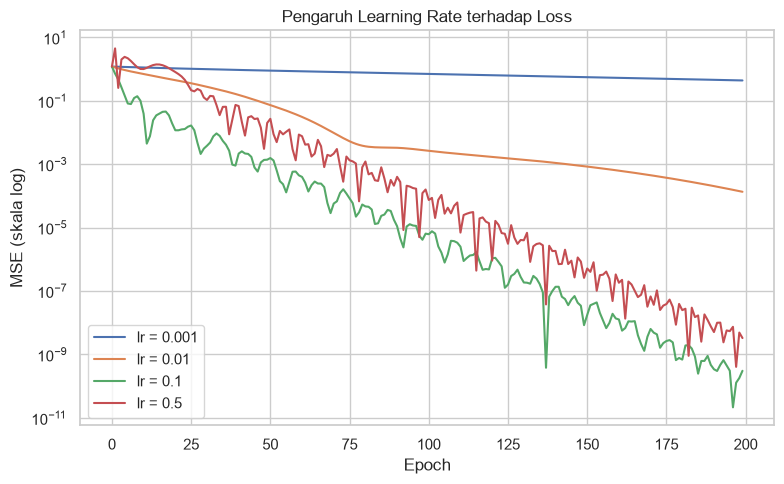

In [ ]:
tabel_lr = pd.DataFrame([
    {'Learning rate': lr,
     'Loss awal': hasil_lr[lr]['history'][0],
     'Loss akhir': hasil_lr[lr]['history'][-1],
     'MSE 5 titik': hasil_lr[lr]['mse_asli'],
     'R2 5 titik': hasil_lr[lr]['r2'],
     'Prediksi luas 90 m2': hasil_lr[lr]['prediksi'][-1]}
    for lr in daftar_lr
])
display(tabel_lr.round(4))

plt.figure(figsize=(8, 5))
for lr in daftar_lr:
    plt.plot(hasil_lr[lr]['history'], label=f'lr = {lr}')
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('MSE (skala log)')
plt.title('Pengaruh Learning Rate terhadap Loss')
plt.legend()
plt.tight_layout()
plt.show()

## Pembahasan Tugas 4

1. **Learning rate 0.001 belum konvergen.** Setelah 200 epoch loss masih 0.4390, dengan MSE 9.307 dan R2 hanya 0.5346. Langkah pembaruan bobot terlalu kecil sehingga model belum mencapai titik optimum pada anggaran epoch yang sama. Model ini berada pada kondisi underfitting.
2. **Learning rate 0.01 jauh lebih baik.** Loss turun ke 0.000135, MSE menjadi 56.14, dan R2 mencapai 0.9972. Model sudah mengenali pola linear antara luas dan harga.
3. **Learning rate 0.1 sedikit lebih unggul.** Loss praktis nol, MSE 40.37, dan R2 0.9980. Penurunan loss terjadi lebih cepat pada epoch-epoch awal dibanding 0.01, meskipun kurvanya mulai terlihat bergerigi (berosilasi) setelah epoch ke-50.
4. **Learning rate 0.5 mencapai hasil hampir sempurna.** MSE mendekati nol dan R2 1.0000. Prediksi untuk luas 90 m2 adalah 899.98, sangat dekat dengan nilai aktual 900. Namun kurvanya paling bergerigi di antara keempat nilai, yang menandakan langkah pembaruan bobot sudah menyentuh batas atas kestabilan.

Urutan hasil ini perlu dibaca dengan konteks dataset. Data dummy hanya berisi lima titik dengan hubungan linear sempurna, sehingga learning rate besar tidak menimbulkan masalah dan justru lebih cepat mencapai solusi. Pada data nyata yang memiliki noise dan skala fitur beragam, learning rate sebesar 0.5 umumnya membuat loss berosilasi atau divergen. Karena itu nilai 0.01 sampai 0.1 lebih lazim dipakai sebagai titik awal, lalu diturunkan bila pelatihan tidak stabil.

Kesimpulan praktis: learning rate terlalu kecil memperlambat konvergensi, sedangkan batas aman nilai besar bergantung pada data. Pada eksperimen ini, rentang 0.01 sampai 0.1 memberi hasil yang sudah sangat baik dengan kurva loss yang halus.

## Dataset Boston dari sumber asli

Fungsi `load_boston` sudah dihapus dari scikit-learn sejak versi 1.2 karena alasan etika pada salah satu atributnya. Sesuai ketentuan tugas, dataset Boston tetap dipakai dan diambil langsung dari sumber aslinya di CMU StatLib, yaitu repositori yang menjadi asal dataset ini sebelum dimasukkan ke scikit-learn.

Struktur berkasnya: 506 baris data, 13 fitur, dan 1 target MEDV (harga rumah dalam ribuan dolar). Setiap baris data terbagi menjadi dua baris teks, sehingga perlu digabung lebih dahulu.

In [ ]:
URL_BOSTON = 'https://lib.stat.cmu.edu/datasets/boston'
URL_CADANGAN = 'https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv'

KOLOM_BOSTON = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE',
                'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']

def load_boston_asli():
    try:
        raw = urllib.request.urlopen(URL_BOSTON, timeout=60).read().decode('utf-8')
        lines = raw.splitlines()
        idx = next(i for i, l in enumerate(lines) if 'Variables in order' in l)
        token = []
        for line in lines[idx + 16:]:
            token.extend(line.split())
        arr = np.array(token, dtype=float)
        if arr.size != 506 * 14:
            raise ValueError(f'Jumlah nilai tidak sesuai: {arr.size}')
        df = pd.DataFrame(arr.reshape(506, 14), columns=KOLOM_BOSTON)
        print('Sumber: CMU StatLib (berkas teks asli)')
        return df
    except Exception as e:
        print('Gagal membaca sumber utama:', e)
        print('Memakai sumber cadangan (CSV)...')
        df = pd.read_csv(URL_CADANGAN)
        print('Sumber: GitHub (CSV)')
        return df


boston = load_boston_asli()
print('Ukuran data:', boston.shape)
display(boston.head())
print(boston.describe().round(2))

Sumber: CMU StatLib (berkas teks asli)
Ukuran data: (506, 14)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


         CRIM      ZN   INDUS    CHAS     NOX      RM     AGE     DIS     RAD     TAX  PTRATIO       B   LSTAT    MEDV
count  506.00  506.00  506.00  506.00  506.00  506.00  506.00  506.00  506.00  506.00   506.00  506.00  506.00  506.00
mean     3.61   11.36   11.14    0.07    0.55    6.28   68.57    3.80    9.55  408.24    18.46  356.67   12.65   22.53
std      8.60   23.32    6.86    0.25    0.12    0.70   28.15    2.11    8.71  168.54     2.16   91.29    7.14    9.20
min      0.01    0.00    0.46    0.00    0.38    3.56    2.90    1.13    1.00  187.00    12.60    0.32    1.73    5.00
25%      0.08    0.00    5.19    0.00    0.45    5.89   45.02    2.10    4.00  279.00    17.40  375.38    6.95   17.02
50%      0.26    0.00    9.69    0.00    0.54    6.21   77.50    3.21    5.00  330.00    19.05  391.44   11.36   21.20
75%      3.68   12.50   18.10    0.00    0.62    6.62   94.07    5.19   24.00  666.00    20.20  396.22   16.96   25.00
max     88.98  100.00   27.74    1.00    0.87   

## Pelatihan MLP untuk regresi Boston

Alur mengikuti jobsheet: standardisasi fitur, split 80:20, model 64 dan 32 neuron ReLU, Adam dengan learning rate 0.001, 200 epoch, lalu plot MSE dan MAE.

In [ ]:
Xb = boston.drop(columns=['MEDV']).values
yb = boston['MEDV'].values

scaler_b = StandardScaler()
Xb_s = scaler_b.fit_transform(Xb)

Xb_train, Xb_val, yb_train, yb_val = train_test_split(
    Xb_s, yb, test_size=0.2, random_state=42
)

tf.keras.utils.set_random_seed(SEED)
model_boston = keras.Sequential([
    keras.Input(shape=(Xb_train.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(1),
])
model_boston.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                     loss='mse', metrics=['mae'])

mulai = time.perf_counter()
h_boston = model_boston.fit(Xb_train, yb_train,
                            validation_data=(Xb_val, yb_val),
                            epochs=200, batch_size=32, verbose=0)
print(f'Waktu pelatihan: {time.perf_counter() - mulai:.2f} detik')

Waktu pelatihan: 29.10 detik


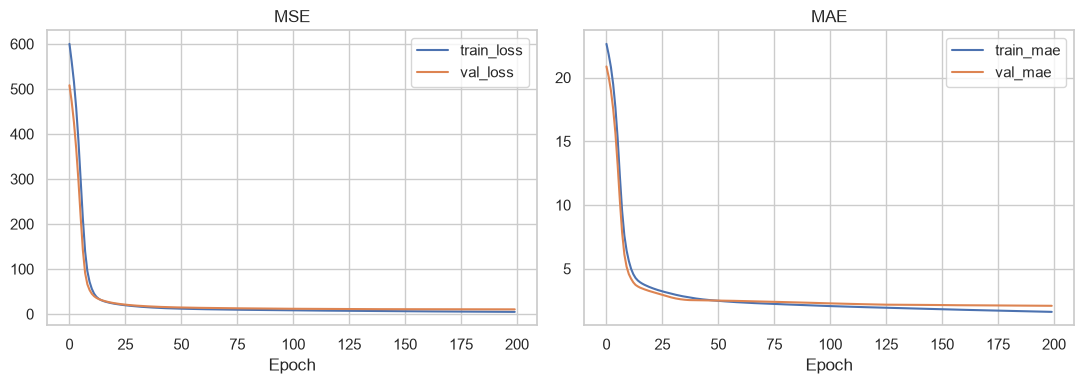

In [ ]:
plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(h_boston.history['loss'], label='train_loss')
plt.plot(h_boston.history['val_loss'], label='val_loss')
plt.legend()
plt.title('MSE')
plt.xlabel('Epoch')

plt.subplot(1, 2, 2)
plt.plot(h_boston.history['mae'], label='train_mae')
plt.plot(h_boston.history['val_mae'], label='val_mae')
plt.legend()
plt.title('MAE')
plt.xlabel('Epoch')

plt.tight_layout()
plt.show()

RMSE : 3.2271 (ribu dolar)
MAE  : 2.0953 (ribu dolar)
R2   : 0.8580


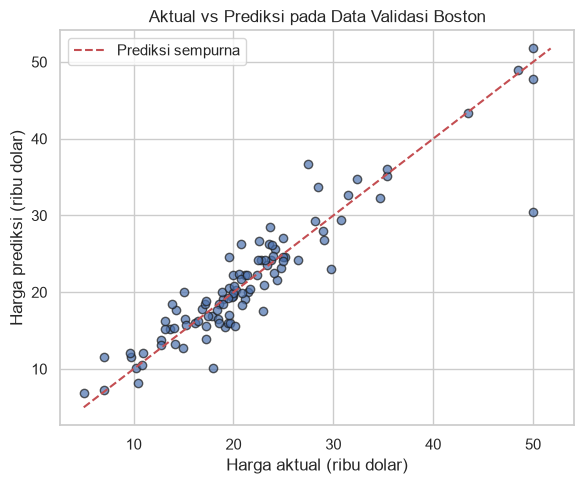

In [ ]:
pred_boston = model_boston.predict(Xb_val, verbose=0).ravel()

rmse = np.sqrt(mean_squared_error(yb_val, pred_boston))
mae = np.mean(np.abs(yb_val - pred_boston))
r2 = r2_score(yb_val, pred_boston)

print(f'RMSE : {rmse:.4f} (ribu dolar)')
print(f'MAE  : {mae:.4f} (ribu dolar)')
print(f'R2   : {r2:.4f}')

plt.figure(figsize=(6, 5))
plt.scatter(yb_val, pred_boston, alpha=0.7, edgecolor='k')
batas = [min(yb_val.min(), pred_boston.min()), max(yb_val.max(), pred_boston.max())]
plt.plot(batas, batas, 'r--', label='Prediksi sempurna')
plt.xlabel('Harga aktual (ribu dolar)')
plt.ylabel('Harga prediksi (ribu dolar)')
plt.title('Aktual vs Prediksi pada Data Validasi Boston')
plt.legend()
plt.tight_layout()
plt.show()

## Pembahasan Praktikum 3

1. Kurva MSE dan MAE sama-sama turun tajam pada 20 epoch pertama, lalu melandai. Tidak ada tanda divergensi. Loss latih berakhir di 4.82 dan loss validasi 10.41, sedangkan MAE berakhir di 1.62 dan 2.10. Selisih ini menandakan model sedikit lebih hafal data latih, tetapi belum sampai overfitting berat karena kurva validasi tetap stabil dan tidak naik.
2. Nilai RMSE 3.23 ribu dolar dan MAE 2.10 ribu dolar berarti kesalahan prediksi rata-rata sekitar 2 ribu dolar, wajar untuk rentang harga 5 sampai 50 ribu dolar. R2 sebesar 0.8580 menunjukkan model menjelaskan sekitar 86 persen variasi harga rumah.
3. Sebaran titik pada grafik aktual vs prediksi mengikuti garis diagonal. Kesalahan paling besar terjadi pada rumah berharga di atas 40 ribu dolar, dengan MAE 4.82 pada lima sampel validasi, dibandingkan MAE 1.88 sampai 2.11 pada rentang harga di bawah 40 ribu. Penyebabnya, rumah mahal sangat sedikit pada dataset sehingga model kurang terlatih pada rentang tersebut. Nilai MEDV juga terpotong pada 50 ribu, yang membatasi pembelajaran pada harga sangat tinggi.
4. Standardisasi fitur penting pada dataset ini karena skala antar fitur sangat berbeda, misalnya TAX berada pada ratusan sedangkan NOX di bawah 1. Tanpa standardisasi, gradient descent akan bergerak tidak seimbang pada tiap fitur.

# Bagian 5: Tugas Praktikum - Klasifikasi Angka Tulisan Tangan (MNIST)

MNIST berisi 70.000 citra angka tulisan tangan berukuran 28 x 28 piksel, terbagi menjadi 60.000 data latih dan 10.000 data uji, dengan 10 kelas (angka 0 sampai 9). Dataset diunduh otomatis oleh Keras.

## Langkah 1: Memuat dan menyiapkan data

Setiap citra diubah menjadi vektor 784 nilai dengan rentang 0 sampai 1, lalu label diubah menjadi one-hot encoding.

In [ ]:
(X_train_m, y_train_m), (X_test_m, y_test_m) = keras.datasets.mnist.load_data()

X_train_m = X_train_m / 255.0
X_test_m = X_test_m / 255.0

y_train_cat = keras.utils.to_categorical(y_train_m, 10)
y_test_cat = keras.utils.to_categorical(y_test_m, 10)

print('Bentuk data latih:', X_train_m.shape)
print('Bentuk data uji  :', X_test_m.shape)
print('Rentang piksel   :', X_train_m.min(), 'sampai', X_train_m.max())
print('Distribusi kelas latih:')
print(pd.Series(y_train_m).value_counts().sort_index().to_string())

Bentuk data latih: (60000, 28, 28)
Bentuk data uji  : (10000, 28, 28)
Rentang piksel   : 0.0 sampai 1.0
Distribusi kelas latih:
0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949


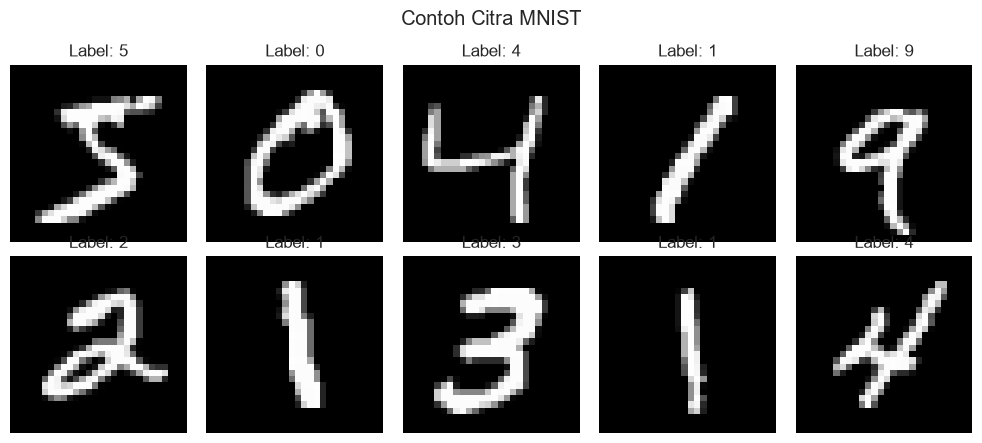

In [ ]:
fig, ax = plt.subplots(2, 5, figsize=(10, 4.5))
for i, axi in enumerate(ax.flat):
    axi.imshow(X_train_m[i], cmap='gray')
    axi.set_title(f'Label: {y_train_m[i]}')
    axi.axis('off')
plt.suptitle('Contoh Citra MNIST')
plt.tight_layout()
plt.show()

## Langkah 2: Membangun model dengan dua hidden layer

Arsitektur dasar mengikuti jobsheet: flatten citra 28 x 28 menjadi 784 nilai, dua hidden layer 128 dan 64 neuron dengan ReLU, lalu output 10 neuron dengan softmax.

In [ ]:
def build_mnist_model(hidden=(128, 64), activation='relu'):
    tf.keras.utils.set_random_seed(SEED)
    model = keras.Sequential()
    model.add(keras.Input(shape=(28, 28)))
    model.add(layers.Flatten())
    for unit in hidden:
        model.add(layers.Dense(unit, activation=activation))
    model.add(layers.Dense(10, activation='softmax'))
    model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model


model_mnist = build_mnist_model(hidden=(128, 64))
model_mnist.summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

## Langkah 3: Melatih model

Pelatihan memakai 5 epoch dengan batch size 128. Sepuluh persen data latih disisihkan sebagai data validasi untuk memantau tanda overfitting.

In [ ]:
mulai = time.perf_counter()
hist_mnist = model_mnist.fit(X_train_m, y_train_cat,
                             epochs=5, batch_size=128,
                             validation_split=0.1, verbose=0)
waktu_mnist = time.perf_counter() - mulai
print(f'Waktu pelatihan: {waktu_mnist:.2f} detik')

Waktu pelatihan: 7.87 detik


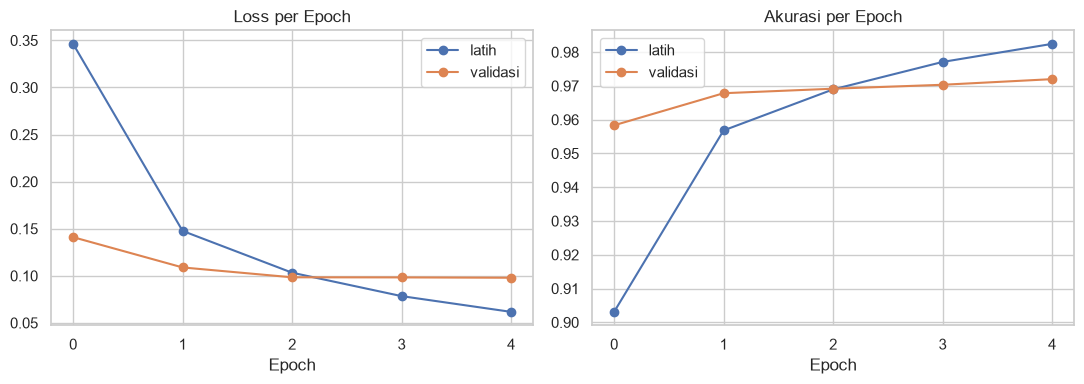

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
epok = range(len(hist_mnist.history['loss']))

ax[0].plot(epok, hist_mnist.history['loss'], marker='o', label='latih')
ax[0].plot(epok, hist_mnist.history['val_loss'], marker='o', label='validasi')
ax[0].set_title('Loss per Epoch')
ax[0].set_xlabel('Epoch')
ax[0].set_xticks(list(epok))
ax[0].legend()

ax[1].plot(epok, hist_mnist.history['accuracy'], marker='o', label='latih')
ax[1].plot(epok, hist_mnist.history['val_accuracy'], marker='o', label='validasi')
ax[1].set_title('Akurasi per Epoch')
ax[1].set_xlabel('Epoch')
ax[1].set_xticks(list(epok))
ax[1].legend()

plt.tight_layout()
plt.show()

## Langkah 4: Evaluasi akurasi pada data uji

In [ ]:
loss_mnist, acc_mnist = model_mnist.evaluate(X_test_m, y_test_cat, verbose=0)
print(f'Loss pada data uji    : {loss_mnist:.4f}')
print(f'Akurasi pada data uji : {acc_mnist:.4f}')

proba_mnist = model_mnist.predict(X_test_m, verbose=0)
pred_mnist = np.argmax(proba_mnist, axis=1)

print()
print(classification_report(y_test_m, pred_mnist, digits=4, zero_division=0))

Loss pada data uji    : 0.1020
Akurasi pada data uji : 0.9688



              precision    recall  f1-score   support

           0     0.9807    0.9857    0.9832       980
           1     0.9902    0.9789    0.9845      1135
           2     0.9520    0.9806    0.9661      1032
           3     0.9376    0.9812    0.9589      1010
           4     0.9805    0.9715    0.9760       982
           5     0.9694    0.9585    0.9639       892
           6     0.9771    0.9812    0.9792       958
           7     0.9819    0.9494    0.9654      1028
           8     0.9394    0.9713    0.9551       974
           9     0.9812    0.9286    0.9542      1009

    accuracy                         0.9688     10000
   macro avg     0.9690    0.9687    0.9686     10000
weighted avg     0.9692    0.9688    0.9688     10000



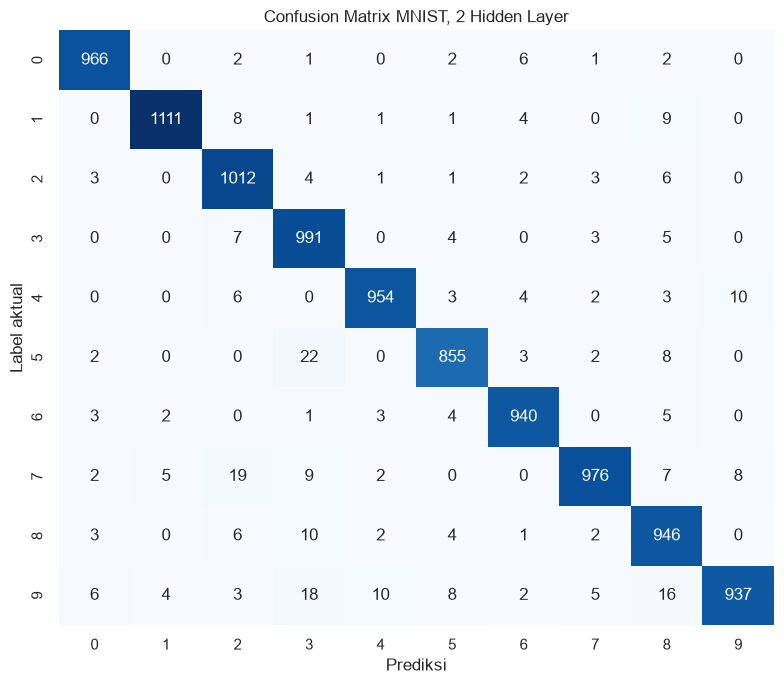

In [ ]:
cm_mnist = confusion_matrix(y_test_m, pred_mnist, labels=list(range(10)))

plt.figure(figsize=(8, 7))
sns.heatmap(cm_mnist, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Prediksi')
plt.ylabel('Label aktual')
plt.title('Confusion Matrix MNIST, 2 Hidden Layer')
plt.tight_layout()
plt.show()

## Langkah 5: Kurva ROC dan AUC multikelas

Untuk 10 kelas, ROC dihitung dengan pendekatan one versus rest, lalu AUC dirata-ratakan. Nilai ini memberi gambaran seberapa baik model memisahkan setiap angka dari sembilan angka lainnya.

AUC macro: 0.9993

AUC per kelas:
  angka 0: 0.9998
  angka 1: 0.9997
  angka 2: 0.9994
  angka 3: 0.9993
  angka 4: 0.9996
  angka 5: 0.9995
  angka 6: 0.9997
  angka 7: 0.9994
  angka 8: 0.9986
  angka 9: 0.9984


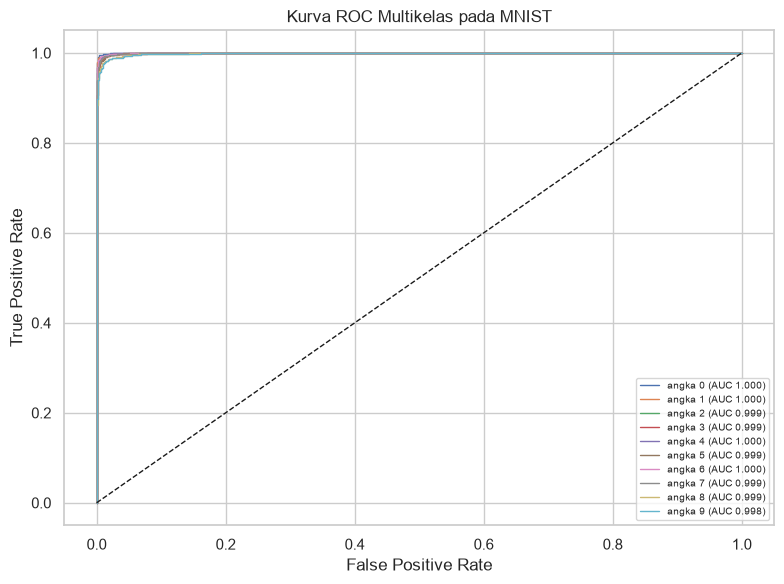

In [ ]:
auc_macro = roc_auc_score(y_test_cat, proba_mnist,
                          multi_class='ovr', average='macro')
auc_per_kelas = roc_auc_score(y_test_cat, proba_mnist,
                              multi_class='ovr', average=None)

print(f'AUC macro: {auc_macro:.4f}')
print()
print('AUC per kelas:')
for digit, nilai in enumerate(auc_per_kelas):
    print(f'  angka {digit}: {nilai:.4f}')

plt.figure(figsize=(8, 6))
for digit in range(10):
    fpr_d, tpr_d, _ = roc_curve(y_test_cat[:, digit], proba_mnist[:, digit])
    plt.plot(fpr_d, tpr_d, lw=1,
             label=f'angka {digit} (AUC {auc_per_kelas[digit]:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Kurva ROC Multikelas pada MNIST')
plt.legend(fontsize=7, loc='lower right')
plt.tight_layout()
plt.show()

## Langkah 6: Eksperimen variasi arsitektur

Tiga variasi dibandingkan dengan konfigurasi dasar:

1. **Dasar:** hidden 128 dan 64, ReLU.
2. **Lebih lebar:** hidden 256 dan 128, ReLU.
3. **Lebih dalam:** hidden 256, 128, dan 64, ReLU.
4. **Aktivasi Sigmoid:** hidden 128 dan 64, Sigmoid.

Semua dijalankan dengan jumlah epoch, batch size, dan optimizer yang sama. Akurasi uji dan waktu pelatihan dicatat.

In [ ]:
skenario = [
    ('Dasar (128-64, ReLU)', (128, 64), 'relu'),
    ('Lebar (256-128, ReLU)', (256, 128), 'relu'),
    ('Dalam (256-128-64, ReLU)', (256, 128, 64), 'relu'),
    ('Sigmoid (128-64)', (128, 64), 'sigmoid'),
]

hasil_mnist = {}

for nama, hidden, act in skenario:
    model = build_mnist_model(hidden=hidden, activation=act)
    mulai = time.perf_counter()
    h = model.fit(X_train_m, y_train_cat, epochs=5, batch_size=128,
                  validation_split=0.1, verbose=0)
    durasi = time.perf_counter() - mulai

    loss_uji, acc_uji = model.evaluate(X_test_m, y_test_cat, verbose=0)
    hasil_mnist[nama] = {
        'model': model, 'history': h.history, 'waktu': durasi,
        'loss_uji': loss_uji, 'acc_uji': acc_uji,
        'parameter': model.count_params(),
        'hidden': hidden, 'activation': act,
    }
    print(f'{nama:<26} | akurasi uji {acc_uji:.4f} | loss uji {loss_uji:.4f} | '
          f'parameter {model.count_params():>9,} | waktu {durasi:6.2f} s')

Dasar (128-64, ReLU)       | akurasi uji 0.9688 | loss uji 0.1020 | parameter   109,386 | waktu   7.84 s


Lebar (256-128, ReLU)      | akurasi uji 0.9731 | loss uji 0.0836 | parameter   235,146 | waktu  10.04 s


Dalam (256-128-64, ReLU)   | akurasi uji 0.9731 | loss uji 0.0844 | parameter   242,762 | waktu  10.63 s


Sigmoid (128-64)           | akurasi uji 0.9556 | loss uji 0.1454 | parameter   109,386 | waktu   7.85 s


In [ ]:
tabel_mnist = pd.DataFrame([
    {'Skenario': nama,
     'Hidden layer': str(hasil_mnist[nama]['hidden']),
     'Aktivasi': hasil_mnist[nama]['activation'],
     'Jumlah parameter': hasil_mnist[nama]['parameter'],
     'Akurasi uji': hasil_mnist[nama]['acc_uji'],
     'Loss uji': hasil_mnist[nama]['loss_uji'],
     'Waktu latih (s)': hasil_mnist[nama]['waktu']}
    for nama, _, _ in skenario
])
display(tabel_mnist.round(4))

,Skenario,Hidden layer,Aktivasi,Jumlah parameter,Akurasi uji,Loss uji,Waktu latih (s)
0,"Dasar (128-64, ReLU)","(128, 64)",relu,109386,0.9688,0.1020,7.8370
1,"Lebar (256-128, ReLU)","(256, 128)",relu,235146,0.9731,0.0836,10.0390
2,"Dalam (256-128-64, ReLU)","(256, 128, 64)",relu,242762,0.9731,0.0844,10.6271
3,Sigmoid (128-64),"(128, 64)",sigmoid,109386,0.9556,0.1454,7.8456


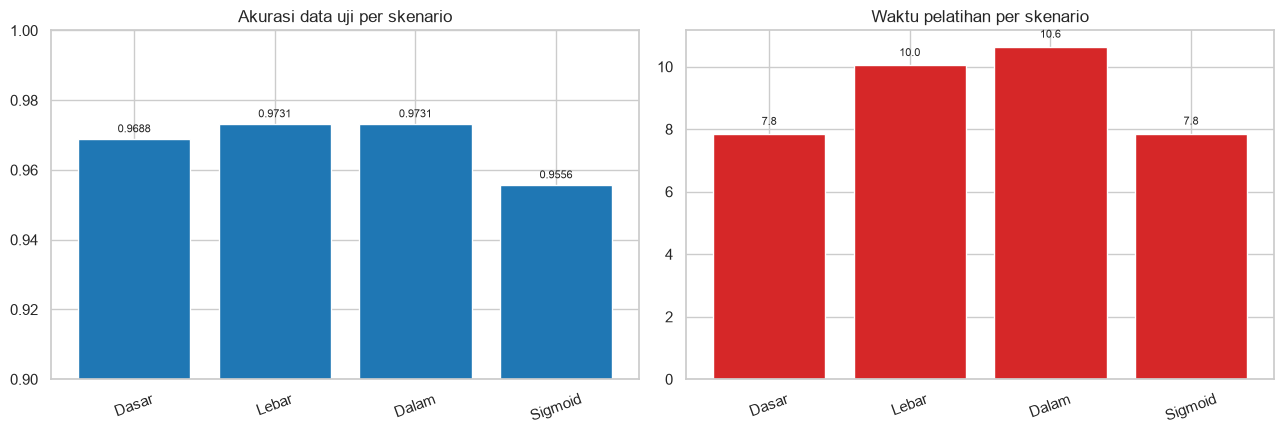

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
nama_singkat = [n.split(' (')[0] for n, _, _ in skenario]

ax[0].bar(nama_singkat, tabel_mnist['Akurasi uji'], color='tab:blue')
ax[0].set_ylim(0.9, 1.0)
ax[0].set_title('Akurasi data uji per skenario')
ax[0].tick_params(axis='x', rotation=20)
for i, v in enumerate(tabel_mnist['Akurasi uji']):
    ax[0].text(i, v + 0.002, f'{v:.4f}', ha='center', fontsize=8)

ax[1].bar(nama_singkat, tabel_mnist['Waktu latih (s)'], color='tab:red')
ax[1].set_title('Waktu pelatihan per skenario')
ax[1].tick_params(axis='x', rotation=20)
for i, v in enumerate(tabel_mnist['Waktu latih (s)']):
    ax[1].text(i, v + 0.3, f'{v:.1f}', ha='center', fontsize=8)

plt.tight_layout()
plt.show()

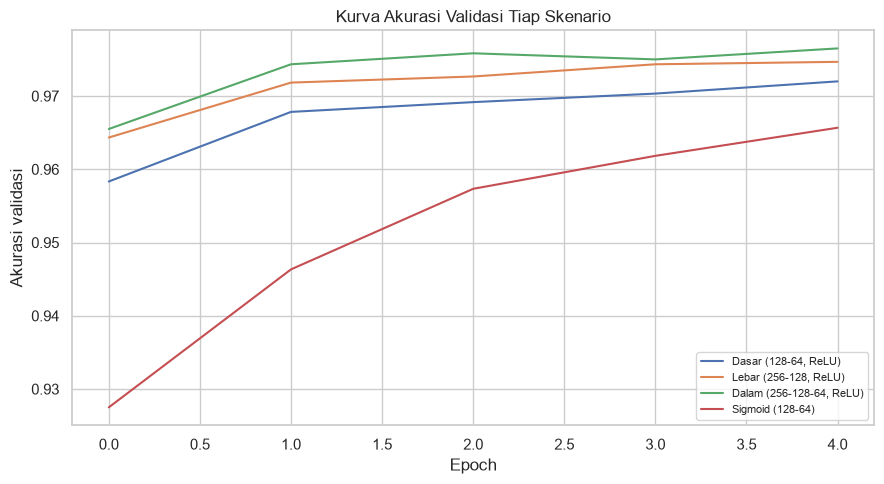

In [ ]:
plt.figure(figsize=(9, 5))
for nama, _, _ in skenario:
    plt.plot(hasil_mnist[nama]['history']['val_accuracy'], label=nama)
plt.xlabel('Epoch')
plt.ylabel('Akurasi validasi')
plt.title('Kurva Akurasi Validasi Tiap Skenario')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Langkah 7: Analisis kesalahan prediksi

Selain akurasi, penting untuk melihat pasangan angka yang paling sering tertukar. Informasi ini menunjukkan di mana model masih lemah.

In [ ]:
salinan = cm_mnist.copy()
np.fill_diagonal(salinan, 0)

pasangan = []
for i in range(10):
    for j in range(10):
        if i != j and salinan[i, j] > 0:
            pasangan.append({'Aktual': i, 'Prediksi': j,
                             'Jumlah': int(salinan[i, j])})

pasangan_df = pd.DataFrame(pasangan).sort_values('Jumlah', ascending=False)
print('Lima pasangan paling sering tertukar:')
display(pasangan_df.head(5).reset_index(drop=True))

benar = np.trace(cm_mnist)
salah = cm_mnist.sum() - benar
print(f'Prediksi benar: {benar} dari {cm_mnist.sum()} ({benar / cm_mnist.sum():.4f})')
print(f'Prediksi salah: {salah}')

Lima pasangan paling sering tertukar:


,Aktual,Prediksi,Jumlah
0,5,3,22
1,7,2,19
2,9,3,18
3,9,8,16
4,8,3,10


Prediksi benar: 9688 dari 10000 (0.9688)
Prediksi salah: 312


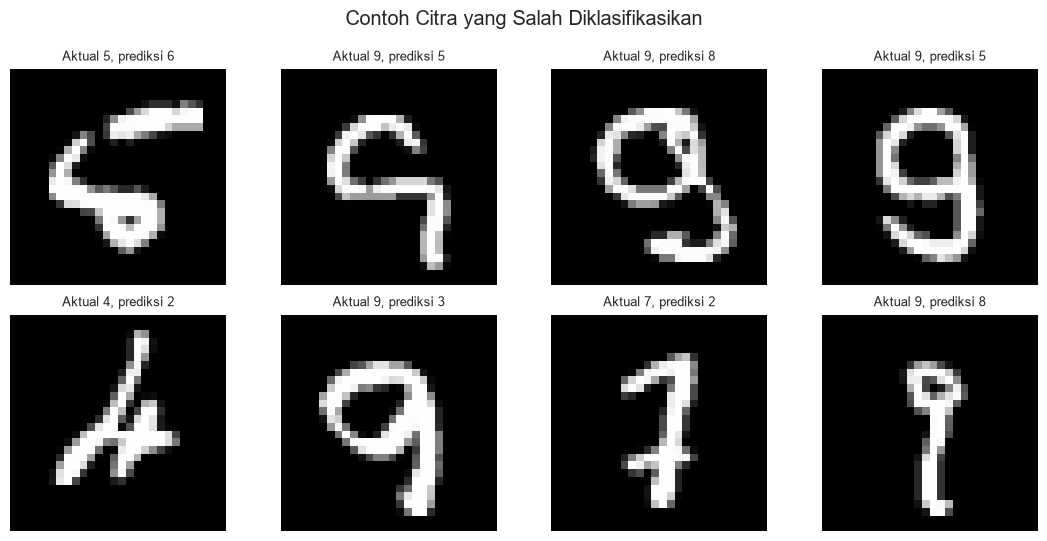

In [ ]:
salah_idx = np.where(pred_mnist != y_test_m)[0][:8]

fig, ax = plt.subplots(2, 4, figsize=(11, 5.5))
for i, axi in enumerate(ax.flat):
    idx = salah_idx[i]
    axi.imshow(X_test_m[idx], cmap='gray')
    axi.set_title(f'Aktual {y_test_m[idx]}, prediksi {pred_mnist[idx]}',
                  fontsize=9)
    axi.axis('off')
plt.suptitle('Contoh Citra yang Salah Diklasifikasikan')
plt.tight_layout()
plt.show()

## Pembahasan Tugas Praktikum

1. **Akurasi dasar.** Model dua hidden layer (128 dan 64) dengan ReLU mencapai akurasi uji 0.9688 dalam 5 epoch, dengan loss 0.1020. Angka ini sudah sangat tinggi untuk model sederhana tanpa convolutional layer, karena JST mempelajari kombinasi bobot pada 784 piksel secara langsung.
2. **Pengaruh jumlah neuron.** Memperlebar hidden layer menjadi 256 dan 128 menaikkan jumlah parameter dari 109.386 menjadi 235.146, tetapi akurasi hanya naik dari 0.9688 ke 0.9731, yaitu sekitar 0.43 poin persen. Loss uji membaik dari 0.1020 ke 0.0836. Tambahan kapasitas ini memberi manfaat, tetapi tidak sebanding dengan kenaikan biaya komputasi.
3. **Pengaruh kedalaman.** Menambah hidden layer ketiga (256, 128, 64) menghasilkan akurasi yang sama dengan model lebar, yaitu 0.9731, dengan 242.762 parameter dan waktu pelatihan paling lama. Pada 5 epoch, kedalaman tambahan belum memberi keunggulan. Jaringan yang lebih dalam umumnya baru unggul setelah dilatih lebih lama dan dipasangi regularisasi seperti dropout.
4. **Sigmoid versus ReLU.** Sigmoid pada hidden layer memberi akurasi 0.9556 dengan loss uji 0.1454, lebih rendah daripada ReLU (0.9688 dan 0.1020). Selisih akurasinya sekitar 1.3 poin persen, tetapi selisih loss-nya cukup besar. Penyebabnya gradien yang menyusut pada 784 fitur input, sehingga Sigmoid butuh epoch jauh lebih banyak untuk mencapai kondisi setara. Inilah alasan ReLU menjadi pilihan standar pada hidden layer.
5. **Kesalahan yang tersisa.** Dari 10.000 data uji, 9.688 prediksi benar dan 312 salah. Pasangan yang paling sering tertukar adalah 5 dengan 3 (22 kasus), 7 dengan 2 (19 kasus), 9 dengan 3 (18 kasus), 9 dengan 8 (16 kasus), dan 8 dengan 3 (10 kasus). Semua pasangan tersebut melibatkan bentuk yang mirip dengan goresan berbeda hanya beberapa piksel, sehingga wajar sulit dibedakan oleh JST yang memperlakukan piksel sebagai vektor datar.
6. **Waktu pelatihan.** Waktu naik seiring jumlah parameter: model dasar sekitar 8 detik, model lebar dan model dalam sekitar 10 detik pada perangkat yang sama. Angka pastinya bergantung pada beban CPU atau GPU saat dijalankan. Model lebar memberi kenaikan akurasi yang kecil dengan tambahan waktu sekitar 20 sampai 30 persen, sehingga konfigurasi dasar paling efisien bila akurasi 0.9688 sudah memadai.
7. **Angka yang paling sulit dikenali.** Dari laporan klasifikasi, angka 9 memiliki recall terendah (0.9286), artinya paling banyak angka 9 yang tidak terdeteksi, yaitu 72 dari 1.009 sampel. Angka 3 dan 8 memiliki precision terendah (0.9376 dan 0.9394) karena sering menjadi tujuan salah prediksi dari angka lain. Angka 0 dan 1 paling mudah dikenali dengan F1 di atas 0.98.

# Bagian 6: Kesimpulan

1. **Evaluasi classifier tidak cukup dengan akurasi.** Confusion matrix memperlihatkan jenis kesalahan yang dibuat model. Pada kasus Iris, seluruh metrik yang dihitung manual dari tabel (accuracy, precision, recall, F1) sama persis dengan keluaran scikit-learn, yaitu akurasi 0.9778 dan kappa 0.9667, sehingga rumus pada jobsheet terbukti benar. Kurva ROC dengan AUC 0.9989 menegaskan pemisahan kelas yang sangat baik.
2. **Perceptron satu lapis hanya mampu menyelesaikan masalah linear.** Gerbang AND berhasil dipelajari dengan sempurna, sedangkan XOR menuntut hidden layer. Backpropagation manual menurunkan loss XOR dari 0.2558 menjadi 0.1282 pada konfigurasi 2 neuron, lalu menjadi 0.0023 saat neuron ditambah menjadi 3, dan 0.00035 saat memakai ReLU.
3. **Keras mempermudah pembangunan JST.** Untuk klasifikasi Iris, arsitektur (10, 8), (16, 16), dan (32, 16) sama-sama mencapai akurasi uji 1.0000, sedangkan (4, 4) hanya 0.6667 karena kurang kapasitas. Fungsi aktivasi juga menentukan: Sigmoid hanya mencapai 0.6667, sementara ReLU mencapai 1.0000 pada anggaran epoch yang sama.
4. **Learning rate sangat menentukan hasil regresi.** Pada data dummy, learning rate 0.001 belum konvergen setelah 200 epoch, sedangkan nilai 0.01 ke atas sudah mencapai loss mendekati nol. Dataset Boston dari sumber asli CMU StatLib dapat dilatih dengan baik, menghasilkan RMSE 3.23 ribu dolar dan R2 0.8580.
5. **Pada MNIST, ReLU lebih unggul daripada Sigmoid.** Model 2 hidden layer (128 dan 64) mencapai akurasi uji 0.9688 dalam 5 epoch, dan naik tipis menjadi 0.9731 saat diperlebar atau diperdalam. Sigmoid hanya mencapai 0.9556. Penambahan neuron dan layer menaikkan biaya komputasi lebih besar daripada kenaikan akurasi yang diperoleh.

## Ringkasan hasil utama

| Bagian | Konfigurasi | Hasil |
|---|---|---|
| Praktikum 1 | XOR, hidden 2, sigmoid | Loss akhir 0.1282, gagal konvergen |
| Praktikum 1 | XOR, hidden 3, sigmoid | Loss 0.0023, prediksi benar |
| Praktikum 1 | XOR, hidden 3, ReLU | Loss 0.00035, konvergen pada epoch 1117 |
| Praktikum 2 | Iris, 10-8, ReLU | Akurasi uji 1.0000, loss 0.2780 |
| Praktikum 2 | Iris, 4-4, ReLU | Akurasi uji 0.6667, underfitting |
| Praktikum 2 | Iris, Sigmoid vs ReLU | 0.6667 vs 1.0000 |
| Praktikum 3 | Regresi dummy, lr 0.001 | Belum konvergen, loss 0.4390 |
| Praktikum 3 | Regresi dummy, lr 0.01 | Loss 0.000135 |
| Praktikum 3 | Boston, 64-32, Adam 1e-3 | RMSE 3.23, MAE 2.10, R2 0.8580 |
| Tugas Praktikum | MNIST, 128-64, ReLU | Akurasi uji 0.9688, AUC macro 0.9993 |
| Tugas Praktikum | MNIST, 256-128, ReLU | Akurasi uji 0.9731 |
| Tugas Praktikum | MNIST, Sigmoid | Akurasi uji 0.9556 |